# Team member(s):

If you export an `.ipynb` file from Kaggle, upon submitting your code on Canvas, please type the names of the team members here:

- Member 1:
- Member 2:

### UMKC Fall 2025 CS 5590/Math 5555 Final project advanced starter 2

This is the advanced starter code for the final project. Please walk it through.
You can download this starter as a notebook and upload it to Colab, or directly run it on Kaggle.
Do not attempt to run the code locally unless there is a GPU supporting CUDA.
All the given models are fairly large (> 10 million parameters) and we only about 30 GPU hours on Kaggle per week.
So please plan accordingly and do not start the final project in the last two weeks.

The end date of this competition is **Dec 20, 2025**.

The due date for submitting the final project report is **Dec 21, 2025**.

## Changes from the advanced starter:
- A K-fold validation strategy is added: monitoring the accuracy on 1-fold.
- A variant of SGD is implemented using Homework 7's problem 1 code with built-in inplace operations.
- A learning rate scheduler is added
- Tracking and plot the loss function values on train and validation set

## Things to try:
- Writing your own learning rate scheduler.
- Implement [RMSprop](https://optimization.cbe.cornell.edu/index.php?title=RMSProp#RMSProp) and [AdaDelta](https://optimization.cbe.cornell.edu/index.php?title=AdaGrad#AdaDelta) with momentum term using `torch.optim`'s `Optimizer` template class.

## GPU
On the right tab there is a Notebook config option page, there is GPU toggle under "Notebook options" tab, clicking the Accelerator drop-down menu will reveal your options. Please choose P100 when you plan to run the code. Kaggle has a Tesla P100 GPU which is better than Colab, but we have only 30 hours of GPU computing time reseting per week. Note this should be more than enough computing power to train the baseline model ResNet

In [ ]:
# imports
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torch.nn.functional as F
from sklearn.model_selection import StratifiedKFold
import matplotlib.pyplot as plt

# Use the ! (bang) prefix to run a shell command inside the notebook
!pip install torchinfo

In [ ]:
train = torch.load('/kaggle/input/2025-fall-cs-5590-math-5555-umkc/train.pt')
test = torch.load('/kaggle/input/2025-fall-cs-5590-math-5555-umkc/test.pt')

train_data, train_targets = train['data'], train['label']
test_data = test['data']

In [ ]:
# verifying the shapes
print(f"The shapes of train data, train targets, test data are\n {train_data.size()}, {train_targets.size()}, {test_data.size()}.")

The shapes of train data, train targets, test data are
 torch.Size([40000, 28, 28]), torch.Size([40000]), torch.Size([30000, 28, 28]).


The train set has data and targets given, yet test set has no targets. We have to train models based on the train data to achieve a high score on the leaderboard on the test set.

# Final Project: write an optimizer

We will have 3 given CNN models as follows, and we will write our own optimizer(s) using `torch.optim` interface to optimize the given 3 models. You are free to use any techniques learned in the class to optimize the model. The goal is to optimize the model such that the model(s) trained performs good in the test set with unknown targets.


## Models:
The 3 fixed models we can use are the famous first state-of-art image recognition CNN ResNet: ResNet 18, ResNet 34, and ResNet 509\ [https://pytorch.org/hub/pytorch_vision_resnet/](https://pytorch.org/hub/pytorch_vision_resnet/). Their settings are in the next cell.
The `__init__()` has two parameters:
- `block`: the first type is the `BasicBlock` used for building ResNet, defined in the file (`torchvision.models.resnet`). The other type is `Bottleneck` block, which has a more agressive dimension reduction mechanics.
- `[2, 2, 2, 2]`: Each number denotes the number of `Bottleneck` or `BasicBlock` modules in a "stage". It depends on how deep you want the networks to be. For example, for ResNet18, it is `[2, 2, 2, 2]`; for ResNet34, it is `[3, 4, 6, 3]`.

The full code of ResNet is here: [https://github.com/pytorch/vision/blob/master/torchvision/models/resnet.py](https://github.com/pytorch/vision/blob/master/torchvision/models/resnet.py). We are just gonna import the `torchvision` implementation, and change the first convolutional layer to accept single channel input, and the stride of the first convolutional layer from 2 to 1.

## New optimizer to try:

#### RMSprop
The RMSprop algorithm (non stochastic version) is as follows:
> Choose $w_0$, $\alpha$, $\gamma$, $\epsilon$, and let $s^{(-1)} = 1$ <br><br>
>    For $k=0,1,2, \cdots, M$<br><br>
>    &nbsp;&nbsp;&nbsp;&nbsp;  $s^{(k)} = \gamma s^{(k-1)} + (1 - \gamma)\, \left|\nabla f(w^{(k)})\right|^2$<br><br>
>    &nbsp;&nbsp;&nbsp;&nbsp;    $\displaystyle w^{(k+1)} =  w^{(k)} -  \frac{\alpha} {\sqrt{s^{(k)}+ \epsilon}} \nabla f(w^{(k)})$  
where $\left|\nabla f(w^{(k)})\right|$ denotes the element-wise magnitude of the gradient vector, and the last line's fraction means element-wise division.

An optional optimizer to try would be to adapt RMSprop to the template we have. We are free to implement any from [An overview of gradient descent optimization algorithms](https://www.ruder.io/optimizing-gradient-descent). Note that most of the algorithm have their built-in version in `torch.optim` submodule. If you are able to unwrap the official torch code to fit the template, you are welcome to do that as well.


## Validation:

Since you do not have access to the target of the test set, to cross-validate your model, you should split the training samples to two sets using the techniques learned in class: one is training dataset, the other is your validation dataset (so that you have access to the targets of this set). This routine is usually used for Kaggle competitions and in the real world model deployment to ensure the trained model has generalizability to the unseen data. In this starter code, **K-fold** is used (yet only trained on 1 fold).

## Hyperparameter tuning:
Aside from writing our own optimizer, there are quite a few hyperparameter for us to tune to achieve better performance:
- learning rate and/or with a scheduler
- dropout rate
- early stop
- other validation strategy based tuning
It is okay to use autoML package (H2O, Rapids, Optuna, fast.ai) if you know how to write a wrapper of them using the given model.

In [ ]:
from torchvision.models.resnet import ResNet, BasicBlock, Bottleneck

class MyResNet(ResNet):
    def __init__(self,
                 block=BasicBlock,
                 layers=[2, 2, 2, 2],
                 num_classes=10):
        super(MyResNet, self).__init__(block,
                                       layers,
                                       num_classes=num_classes)
        self.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=1, padding=3,bias=False)

        '''
        you can modify the layers in this initialization of ResNet if you like
        '''

# choose 1
resnet18 = {
    "block": BasicBlock,
    "layers": [2, 2, 2, 2]
}

resnet34 = {
    "block": BasicBlock,
    "layers": [3, 4, 6, 3]
}

resnet50 = {
    "block": Bottleneck,
    "layers": [3, 4, 6, 3]
}



model = MyResNet(**resnet18)

In [ ]:
from torchinfo import summary # similar function to tensorflow/keras summary for torch

In [ ]:
batch_size = 64
summary(model, input_size=(batch_size, 1, 28, 28), device='cpu'); # (color_channel, 28, 28)

A batch size of 1024 of float precision training needs about 4GB of RAM for the GPU.

# Prepare the train loader

In [ ]:
batch_size = 64

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# We take the first fold for this starter code
# you can ensemble all folds
train_idx, val_idx = next(skf.split(train_data, train_targets))

In [ ]:
train_idx[:10]

array([ 0,  1,  3,  4,  5,  6,  7,  8,  9, 10])

In [ ]:
val_idx[:10]

array([ 2, 18, 22, 31, 38, 39, 44, 48, 52, 53])

In [ ]:
print(train_data[train_idx].shape)

torch.Size([32000, 28, 28])


In [ ]:
# 1fold
X_tr = train_data[train_idx][:,None,:,:].float()
y_tr = train_targets[train_idx].long()
X_val = train_data[val_idx][:,None,:,:].float()
y_val = train_targets[val_idx].long()

train_set = TensorDataset(X_tr, y_tr)
train_loader = DataLoader(train_set, batch_size=batch_size)

valid_set = TensorDataset(X_val, y_val)
val_loader = DataLoader(valid_set, batch_size=batch_size)

In [ ]:
sample = next(iter(train_loader))
print(sample[0].size(), sample[1].size())

torch.Size([64, 1, 28, 28]) torch.Size([64])


In [ ]:
with torch.no_grad():
    sample_output = model(sample[0]) # verifying the model is okay

print(sample_output.size()) # should be (batch_size, n_classes)

torch.Size([64, 10])


In [ ]:
def zeropower_via_newtonschulz5(G, steps: int):
    """
    Newton-Schulz iteration to compute the zeroth power / orthogonalization of G. We opt to use a
    quintic iteration whose coefficients are selected to maximize the slope at zero. For the purpose
    of minimizing steps, it turns out to be empirically effective to keep increasing the slope at
    zero even beyond the point where the iteration no longer converges all the way to one everywhere
    on the interval. This iteration therefore does not produce UV^T but rather something like US'V^T
    where S' is diagonal with S_{ii}' ~ Uniform(0.5, 1.5), which turns out not to hurt model
    performance at all relative to UV^T, where USV^T = G is the SVD.
    """
    assert G.ndim >= 2 # batched Muon implementation by @scottjmaddox, and put into practice in the record by @YouJiacheng
    a, b, c = (3.4445, -4.7750,  2.0315)
    X = G.bfloat16()
    if G.size(-2) > G.size(-1):
        X = X.mT

    # Ensure spectral norm is at most 1
    X = X / (X.norm(dim=(-2, -1), keepdim=True) + 1e-7)
    # Perform the NS iterations
    for _ in range(steps):
        A = X @ X.mT
        B = b * A + c * A @ A # quintic computation strategy adapted from suggestion by @jxbz, @leloykun, and @YouJiacheng
        X = a * X + B @ X

    if G.size(-2) > G.size(-1):
        X = X.mT
    return X

# Final project: write our own optimizer

In the following cells, we use the `torch.optim` interface to build our own optimizer.
The following code is simplified from an early version of [SGD in PyTorch 1.x](https://docs.pytorch.org/docs/1.9.0/optim.html?highlight=sgd#torch.optim.SGD)

Please refer to the final project page to see requirements of the implementation of a customized optimizer.

In [ ]:
from torch.optim import Optimizer
import math # Need this import for the step function

class Muon(Optimizer):
    """
    Muon - MomentUm Orthogonalized by Newton-schulz

    https://kellerjordan.github.io/posts/muon/

    Muon internally runs standard SGD-momentum, and then performs an orthogonalization post-
    processing step, in which each 2D parameter's update is replaced with the nearest orthogonal
    matrix. For efficient orthogonalization we use a Newton-Schulz iteration, which has the
    advantage that it can be stably run in bfloat16 on the GPU.

    Muon should only be used for hidden weight layers. The input embedding, final output layer,
    and any internal gains or biases should be optimized using a standard method such as AdamW.
    Hidden convolutional weights can be trained using Muon by viewing them as 2D and then
    collapsing their last 3 dimensions.

    Arguments:
        lr: The learning rate, in units of spectral norm per update.
        weight_decay: The AdamW-style weight decay.
        momentum: The momentum. A value of 0.95 here is usually fine.
    """
    def __init__(self,
                 params,
                 lr=0.02,
                 beta=0.95, # momentum
                 ns_steps=5,
                 weight_decay=0.0): # may not need in Muon


        defaults = dict(lr=lr,
                        beta=beta, # <-- The step function reads 'betas' here
                        ns_steps=ns_steps,
                        weight_decay=weight_decay)
        super().__init__(params, defaults)

    def step(self, closure=None):
        loss = None
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue

                if p.ndim < 2:
                    continue

                grad = p.grad
                ns_steps = group['ns_steps']
                beta = group['beta']
                state = self.state[p]

                # State initialization
                if len(state) == 0:
                    state["momentum_buffer"] = torch.zeros_like(p)

                #update = muon_update(grad, state["momentum_buffer"], beta=group["momentum"])
                nesterov = True
                momentum = state["momentum_buffer"]
                momentum.lerp_(grad, 1 - beta)
                update = grad.lerp_(momentum, beta) if nesterov else momentum
                if update.ndim == 4: # for the case of conv filters
                    update = update.view(len(update), -1)
                update = zeropower_via_newtonschulz5(update, steps=ns_steps)
                update *= max(1, grad.size(-2) / grad.size(-1))**0.5
                with torch.no_grad():
                    p.mul_(1 - group["lr"] * group["weight_decay"])
                    p.add_(update.reshape(p.shape), alpha=-group["lr"])
                #p.data.all_gather(params_pad[base_i:base_i + dist.get_world_size()], params_pad[base_i + dist.get_rank()])
                """"
                exp_avg, exp_avg_sq = state['exp_avg'], state['exp_avg_sq']
                beta1, beta2 = group['betas']

                state['step'] += 1

                exp_avg.mul_(beta1).add_(grad, alpha=1 - beta1)
                exp_avg_sq.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)

                denom = exp_avg_sq.sqrt().add_(group['eps'])

                correction1 = 1 - beta1**state['step']
                correction2 = 1 - beta2**state['step']
                step_size = group['lr'] * math.sqrt(correction2) / correction1
                # correction2 is a float thus math.sqrt is used

                p.data.addcdiv_(exp_avg, denom, value=-step_size)
                """
        return loss

## Final project: add a schedular

In [ ]:
from torch.optim.lr_scheduler import ReduceLROnPlateau, _LRScheduler

class MinimalScheduler(_LRScheduler):
    def __init__(self,
                 optimizer,
                 last_epoch=-1):
        """
        Implements a minimal learning rate scheduler
        """
        super().__init__(optimizer, last_epoch)

    def get_lr(self):
        # Implement your logic here to return a list of learning rates for each param group
        # Example: return [group['lr'] * 0.9 for group in self.optimizer.param_groups]
        return [group['lr'] for group in self.optimizer.param_groups]

# Training

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device) # should be cuda if GPU is enabled

cuda


In [ ]:
from tqdm.auto import tqdm
from torch.optim.lr_scheduler import ReduceLROnPlateau # Import scheduler class

# --- RECOMMENDED ADAM HYPERPARAMETERS ---
learning_rate = 0.02
beta = 0.99
epsilon = 1e-8
ns_steps = 5
# ----------------------------------------

# 1. Update the Optimizer Class Name and Parameters
# Change 'SGD' to 'Adam' and use 'betas' instead of 'alpha' and 'momentum'
optimizer = Muon(model.parameters(),
                 lr=learning_rate,
                 beta=beta,
                 ns_steps=ns_steps,# <-- Use the correct Adam parameters
                 weight_decay=0.0
                 )

# 2. Keep the Scheduler (Analysis Below)
# The scheduler is fine as it is, but its meaning depends on factor and patience.
scheduler = ReduceLROnPlateau(optimizer,
                              mode='max',
                              factor=0.1,
                              patience=2)

loss_func = nn.CrossEntropyLoss()

model.to(device);

In [ ]:
epochs = 20
acc_last_epoch = 0.0

train_losses= []
train_accs = []
val_losses = []
val_accs = []
lrs = []
# tensorboard SummaryWriter
# wandb (weights and biases)

for epoch in range(epochs):

    model.train()

    loss_vals = []
    train_acc_accum = []
    acc_on_valid = [0.0] # list the accuracy on validation dataset
    acc_max = 0.0 # current maximum accuracy

    with tqdm(total=len(train_loader)) as pbar:
        for x, targets in train_loader:

            x, targets = x.to(device), targets.to(device)

            # forward pass
            outputs = model(x)

            # loss function
            loss = loss_func(outputs, targets)

            # record loss function values
            loss_vals.append(loss.item())

            # clean the gradient from last iteration
            optimizer.zero_grad()

            # backprop
            loss.backward()

            # gradient descent
            optimizer.step()

            loss_vals.append(loss.item())
            with torch.no_grad():
                preds = outputs.argmax(dim=-1)
                batch_acc = (preds == targets).float().mean().item()
                train_acc_accum.append(batch_acc)

            pbar.set_postfix({
                'loss': f"{np.mean(loss_vals):.4f}",
                'tr_acc': f"{np.mean(train_acc_accum):.4f}"
            })
            pbar.update()

    # record the train losses
    avg_train_loss = np.mean(loss_vals)
    avg_train_acc = np.mean(train_acc_accum)
    train_losses.append(np.mean(loss_vals))

    # check accuracy (simple validation)
    val_loss_epoch = []
    with torch.no_grad():
        for x_v, y_v in val_loader:
            # x_v: validation image
            # y_v: validation target
            x_v, y_v = x_v.to(device), y_v.to(device)
            yhat = model(x_v) # yhat is (batch_size, 10)

            # Calculate validation loss
            v_loss = loss_func(yhat, y_v)
            val_loss_epoch.append(v_loss.item())

            yhat = yhat.argmax(dim=-1) # yhat is (batch_size, )
            acc = (yhat == y_v).float().mean() # checking accuracy for a batch
            acc = acc.cpu().numpy()
            acc_on_valid.append(acc)

        avg_val_loss = np.mean(val_loss_epoch)
        avg_val_acc = np.mean(acc_on_valid)
        val_losses.append(avg_val_loss)
        val_accs.append(avg_val_acc)

          # --- POST-EPOCH LOGGING & SCHEDULER ---
        print(f"\nSummary Epoch {epoch+1}:")
        print(f"Train Loss: {avg_train_loss:.4e} | Train Acc: {avg_train_acc:.4f}")
        print(f"Valid Loss: {avg_val_loss:.4e} | Valid Acc: {avg_val_acc:.4f}")
        gap = avg_train_acc - avg_val_acc
        print(f"Generalization Gap: {gap:.4f}")

        # Apply the scheduler based on validation accuracy
        # different schedulers have different ways to be called
        scheduler.step(avg_val_acc)

        # Track learning rate
        current_lr = optimizer.param_groups[0]['lr']
        lrs.append(current_lr)
        print(f"Current Learning Rate: {current_lr:.3e}") # .4e

        if avg_val_acc > acc_max:
            # np.mean(acc_on_valid):
            # average accuracy for each batch in valid in current epoch
            torch.save(model.state_dict(), f'my_model.pt')
            acc_max = avg_val_acc


  0%|          | 0/500 [00:00<?, ?it/s]


Summary Epoch 1:
Train Loss: 2.9125e-01 | Train Acc: 0.9201
Valid Loss: 1.4312e-01 | Valid Acc: 0.9544
Generalization Gap: -0.0343
Current Learning Rate: 2.000e-02


  0%|          | 0/500 [00:00<?, ?it/s]


Summary Epoch 2:
Train Loss: 1.2466e-01 | Train Acc: 0.9680
Valid Loss: 1.5019e-01 | Valid Acc: 0.9571
Generalization Gap: 0.0109
Current Learning Rate: 2.000e-02


  0%|          | 0/500 [00:00<?, ?it/s]


Summary Epoch 3:
Train Loss: 8.1528e-02 | Train Acc: 0.9778
Valid Loss: 1.1649e-01 | Valid Acc: 0.9697
Generalization Gap: 0.0080
Current Learning Rate: 2.000e-02


... (30 outputs left out)

  0%|          | 0/500 [00:00<?, ?it/s]


Summary Epoch 19:
Train Loss: 1.9573e-04 | Train Acc: 0.9999
Valid Loss: 1.2674e-01 | Valid Acc: 0.9804
Generalization Gap: 0.0195
Current Learning Rate: 2.000e-04


  0%|          | 0/500 [00:00<?, ?it/s]


Summary Epoch 20:
Train Loss: 1.7648e-04 | Train Acc: 0.9999
Valid Loss: 1.2520e-01 | Valid Acc: 0.9799
Generalization Gap: 0.0200
Current Learning Rate: 2.000e-04


## Plot the train/valid loss as a function of iterations

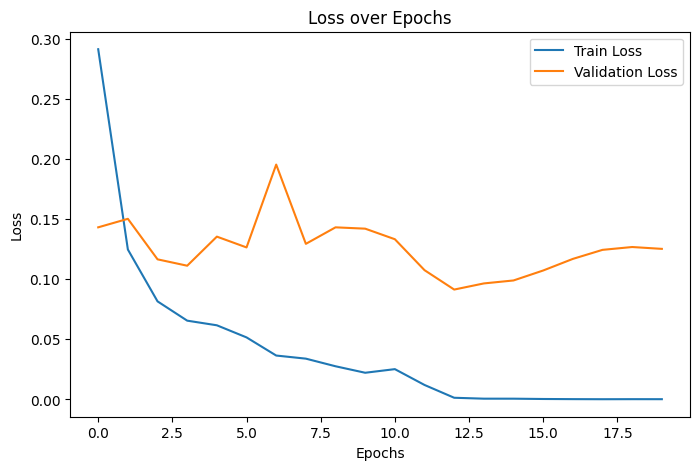

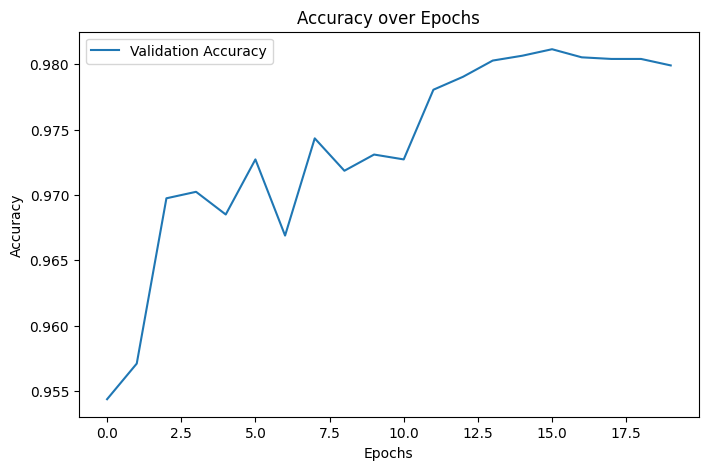

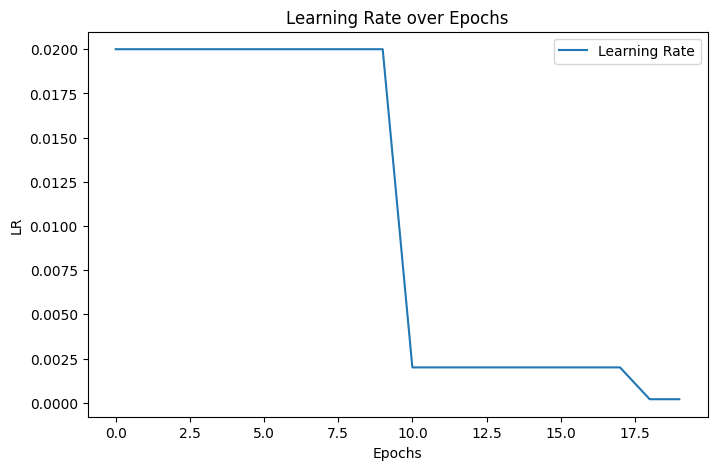

In [ ]:

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss over Epochs')
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(val_accs, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Accuracy over Epochs')
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(lrs, label='Learning Rate')
plt.xlabel('Epochs')
plt.ylabel('LR')
plt.legend()
plt.title('Learning Rate over Epochs')
plt.show()

# Predict the solution on the test set

Evaluate the trained model and generate the `preds` variable, which is the index of the maximum entry of the 10 outputs for each sample.

In [ ]:
model.load_state_dict(torch.load('./my_model.pt', map_location=device))
model.eval(); # this cannot be omitted due to dropout

In [ ]:
test = TensorDataset(test_data[:,None,:,:].float())
test_loader = DataLoader(test, batch_size = batch_size, shuffle = False, drop_last=False)

y_preds = []
for x in tqdm(test_loader):
    with torch.no_grad():
        x = x[0].to(device)
        y_pred = model(x)
        y_preds.append(y_pred.cpu().detach().numpy())

y_preds = np.concatenate(y_preds)
preds = y_preds.argmax(axis=-1).astype(int)
print(preds.shape) # should be 30,000

  0%|          | 0/469 [00:00<?, ?it/s]

(30000,)


# Export the solutions and submit to Kaggle

The result predicted by your model can be named to `preds`, and be exported to a `.csv` file using the following cell. The `y_pred` should be of a dimension `(30000,)` numpy array.

Rename the resulting `solutions-yournames.csv` by replacing `yournames` by your team members' initials connected by hyphen and then save the notebook on Kaggle.

Then click the submit button below, the solution can be submitted directly from the output tab of a committed notebook (click `Save Version` blue button in the interactive kernel window).

In [ ]:
len_test = test_data.size(0)
solutions = np.zeros((test_data.size(0), 2))
solutions[:,0] = np.arange(1,len_test+1)
solutions[:,1] = preds
solutions = solutions.astype(int)
np.savetxt("solutions-rh.csv", solutions,
           fmt='%s', header = 'Id,Category', delimiter = ',', comments='')